# Responses of all ROIs in field GCL3

Supplementary figure (rebuttal): for every 2p ROI of field GCL3 that is mapped to a proofread EM cell,
the morphology, IPL stratification profile, chirp and moving-bar responses, and direction tuning.
The 66 cells are split into three panels of 22 cells each.

# Imports

In [1]:
import os
import sys
from unittest.mock import patch

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import skeliner as sk
from matplotlib.text import Text

In [2]:
sys.path.append("../utils")

import data_2p_loader as data_loader
import data_io
import plot
from skeleton import rotate_skel
from style import set_rc_params

# Data

In [3]:
%%time
config = data_io.get_data_config()
skel_dir = os.path.join(config["root"], "swc")
assert os.path.isdir(skel_dir), skel_dir

df = data_loader.load_df_rois_morph()

CPU times: total: 16.9 s
Wall time: 17.2 s


In [4]:
def add_skels(df):
    df = df.copy()
    df["swc_path"] = df["Latest SegID"].apply(lambda x: os.path.join(skel_dir, f"{x}.swc"))
    df["skel"] = df["swc_path"].apply(lambda p: sk.io.load_swc(p) if os.path.isfile(p) else None)
    return df

In [5]:
field = "GCL3"

df_field = add_skels(df[df["2p-Field"] == field])
assert df_field["skel"].notnull().all(), "missing skeletons"
print(f"{field}: {len(df_field)} cells")

C:\Users\joesterle\AppData\Local\Temp\ipykernel_12048\4242788973.py:4: DeprecationWarning: load_swc() is deprecated, use load_skeleton_swc() instead.
  df["skel"] = df["swc_path"].apply(lambda p: sk.io.load_swc(p) if os.path.isfile(p) else None)


GCL3: 66 cells


# Plot

In [6]:
set_rc_params()
mpl.rcParams["svg.fonttype"] = "none"  # keep text editable in the svg

fig_dir = "../figures/calcium_data"
os.makedirs(fig_dir, exist_ok=True)

In [7]:
def plot_morph(ax, skel):
    """Top view of the dendrites (soma at the origin) with an adaptive vertical scale bar."""
    skel_rot = rotate_skel(skel, rotation_deg=150)
    skel_rot.nodes -= np.asarray(skel_rot.soma.center)

    nodes = skel_rot.nodes[skel_rot.ntype == 3]
    if len(nodes) == 0:
        nodes = skel_rot.nodes

    # plane="yx": horizontal coordinate is y, vertical is x; include the soma in the bounds
    coords = np.vstack((nodes[:, [1, 0]], [[0.0, 0.0]]))
    lower, upper = coords.min(axis=0), coords.max(axis=0)
    extent = max(np.max(upper - lower), 1.0)

    # extra space on the left for the scale bar
    xlim = (lower[0] - 0.25 * extent, upper[0] + 0.08 * extent)
    ylim = (lower[1] - 0.08 * extent, upper[1] + 0.08 * extent)

    # sk.plot.projection calls plt.tight_layout(), which would undo the fixed grid layout
    with patch.object(plt, "tight_layout"):
        sk.plot.projection(skel_rot, ax=ax, xlim=xlim, ylim=ylim, plane="yx", draw_cylinders=False)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal", adjustable="box")

    # scale bar: largest 1/2/5 x 10^n that is at most a quarter of the panel height
    yspan = ylim[1] - ylim[0]
    target = 0.25 * yspan
    candidates = 10 ** np.floor(np.log10(target)) * np.array([1, 2, 5])
    bar_size = candidates[candidates <= target].max()
    bar_fraction = bar_size / yspan

    ax.plot([-0.10, -0.10], [0.08, 0.08 + bar_fraction], transform=ax.transAxes,
            color="k", lw=0.8, clip_on=False)
    ax.text(-0.08, 0.08 + bar_fraction / 2, f"{bar_size:g} µm", transform=ax.transAxes,
            rotation=90, ha="left", va="center", fontsize=6)

    ax.set_rasterized(True)


def plot_cells(df, figsize=None, fontsize_factor=1, row_gap=0.5):
    """One row per cell: header, morphology, IPL profile, chirp, moving bar, direction tuning."""
    n_rows = len(df)
    if n_rows == 0:
        raise ValueError("The DataFrame contains no cells to plot.")

    if figsize is None:
        figsize = (8, n_rows * 1.2)

    # gaps add to the figure height, so the height of each cell row stays fixed
    cell_height = figsize[1] / n_rows
    gap_height = cell_height * row_gap / (0.22 + 1.0)
    figsize = (figsize[0], figsize[1] + (n_rows - 1) * gap_height)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(
        nrows=3 * n_rows - 1,
        ncols=5,
        left=0.02, right=0.98, bottom=0.01, top=0.99, wspace=0.15, hspace=0,
        width_ratios=(1.5, 0.5, 1.6, 1.6, 0.6),
        # each cell: header, content, then an empty spacer row (except after the last)
        height_ratios=([0.22, 1.0, row_gap] * n_rows)[:-1],
    )

    axs = np.empty((n_rows, 5), dtype=object)

    for i, (_, row) in enumerate(df.iterrows()):
        header_ax = fig.add_subplot(gs[3 * i, :])
        header_ax.axis("off")
        label = (
            f"ROI: {row['roi_id']}, {row['Cell Type']}\n"
            rf"$QI_{{\mathrm{{chirp}}}}$: {row['chirp_qidx']:.2f}, "
            rf"$QI_{{\mathrm{{bar}}}}$: {row['bar_qidx']:.2f}"
        )
        header_ax.text(0, 0.5, label, transform=header_ax.transAxes,
                       ha="left", va="center", fontsize=8).set_in_layout(False)

        for j in range(5):
            axs[i, j] = fig.add_subplot(gs[3 * i + 1, j], projection="polar" if j == 4 else None)

        plot_morph(axs[i, 0], row["skel"])
        plot.plot_ipl_profile(ax=axs[i, 1], row=row)
        plot.plot_chirp(ax=axs[i, 2], row=row)
        plot.plot_bar(ax=axs[i, 3], row=row, annotate_dirs=False, annotate_symbols=i == 0, ventral_up=False)
        plot.plot_bar_dir(ax=axs[i, 4], row=row, ventral_up=False)

        for ax in axs[i, 2:4]:
            if i == n_rows - 1:
                plot.plot_scale_bar(ax=ax, x0=1, y0=-0.4, size=2, text=True, tdist=0.05, unit="s")
            ax.set_ylim(-0.5, 1.1)

    for ax in axs[:, :-1].flat:
        ax.set(xlabel=None, ylabel=None, xticks=[], yticks=[])
        ax.axis("off")
        ax.set_facecolor((1, 1, 1, 0))

    for text in fig.findobj(match=Text):
        text.set_fontsize(text.get_fontsize() * fontsize_factor)

    return fig, axs

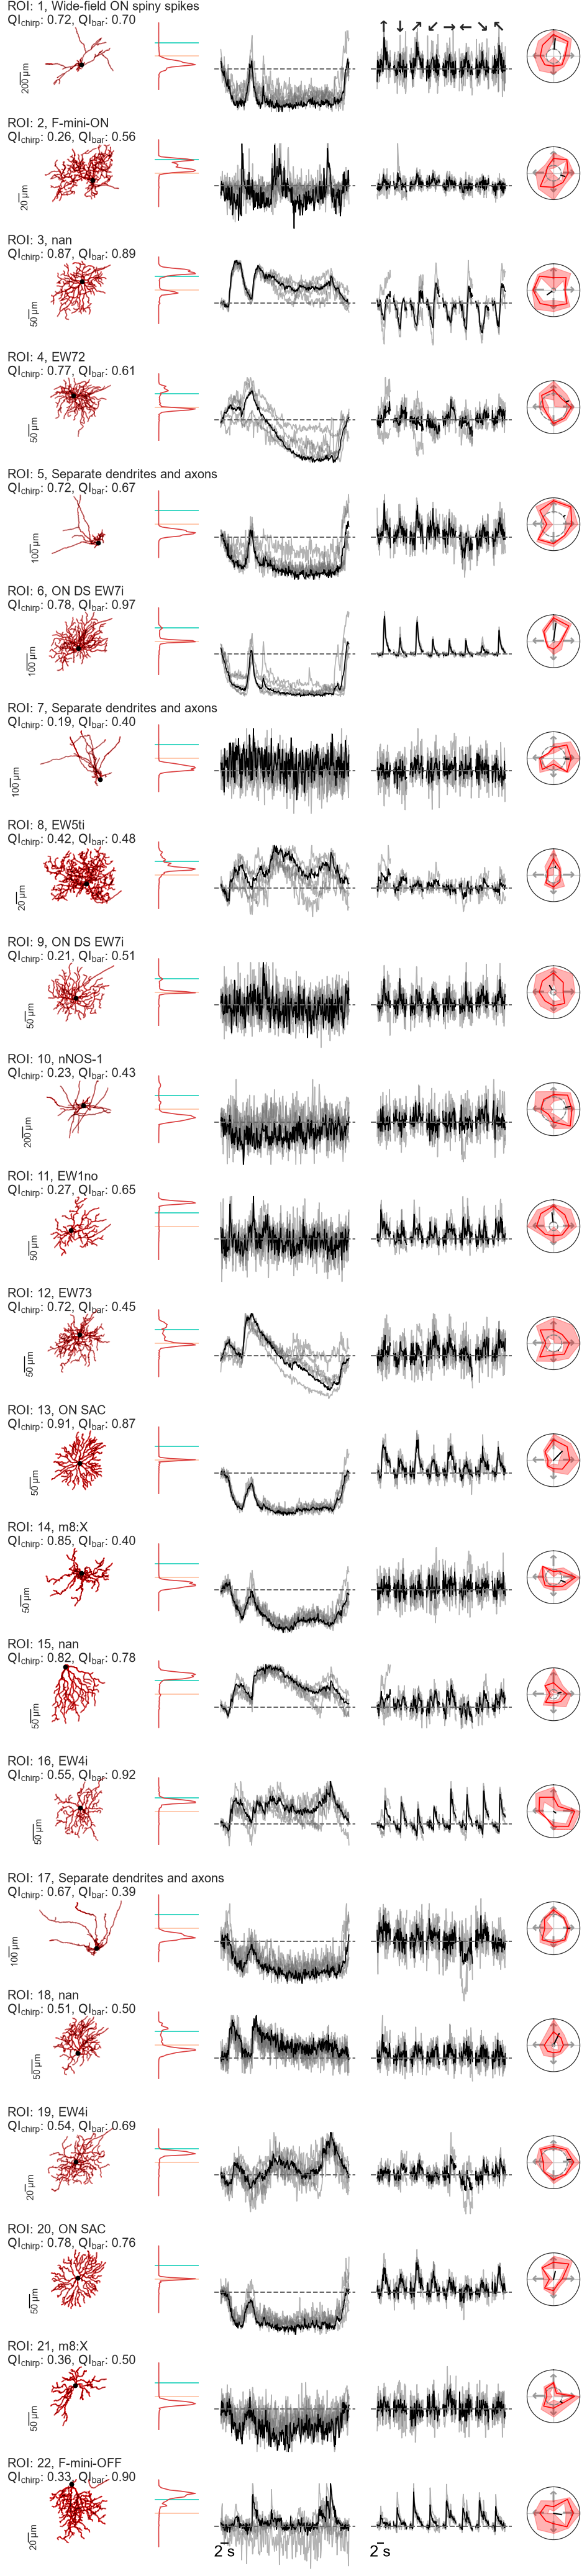

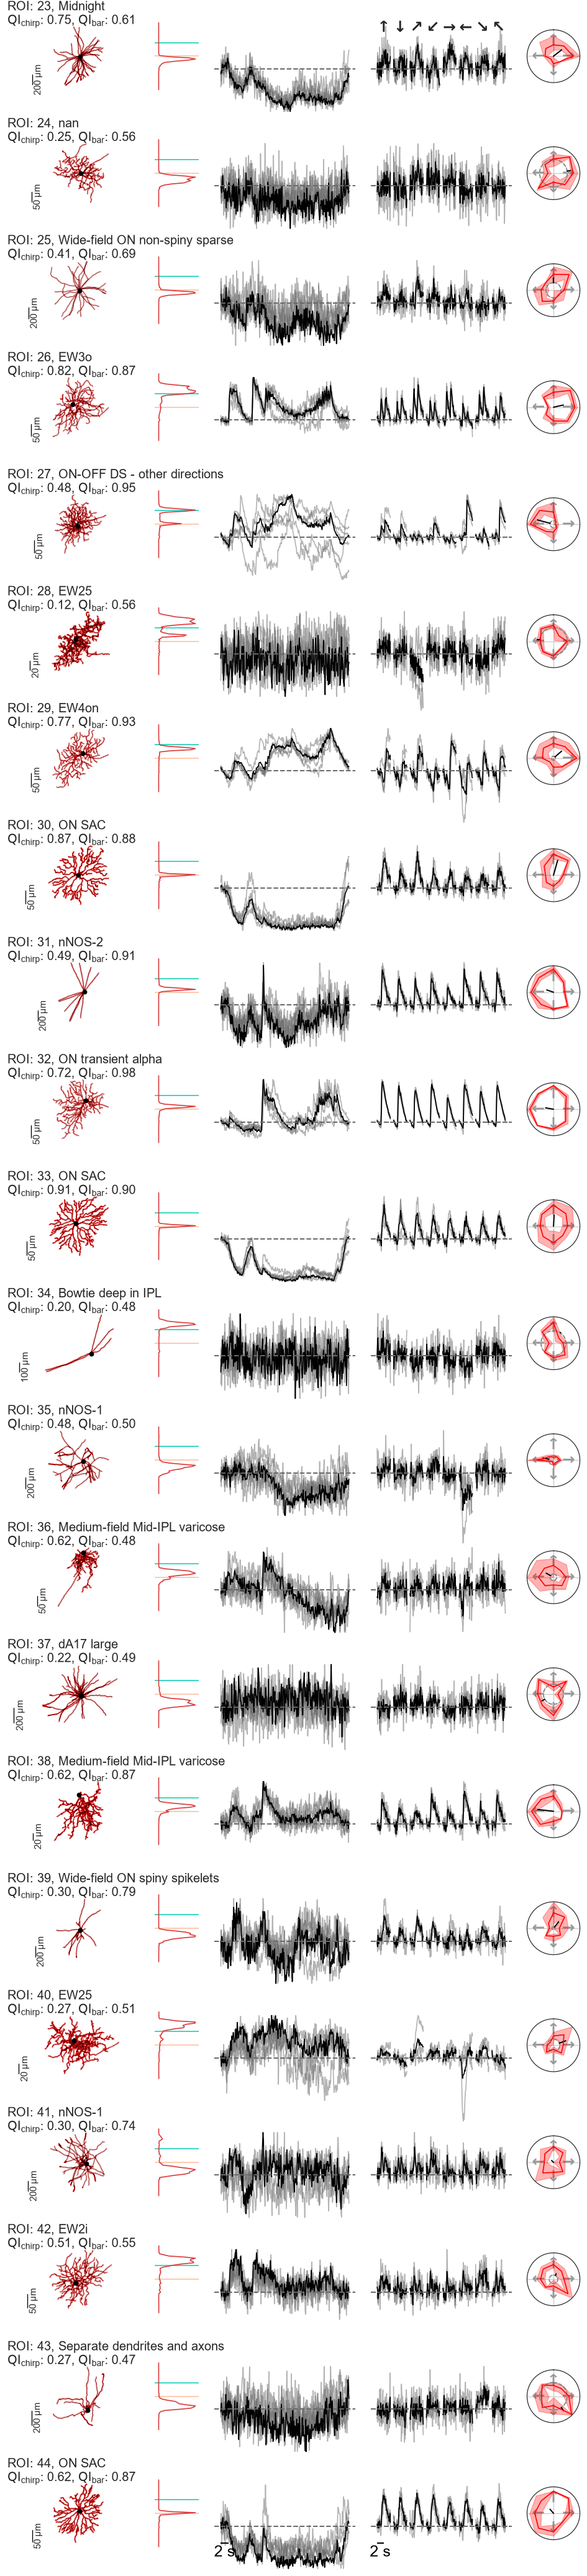

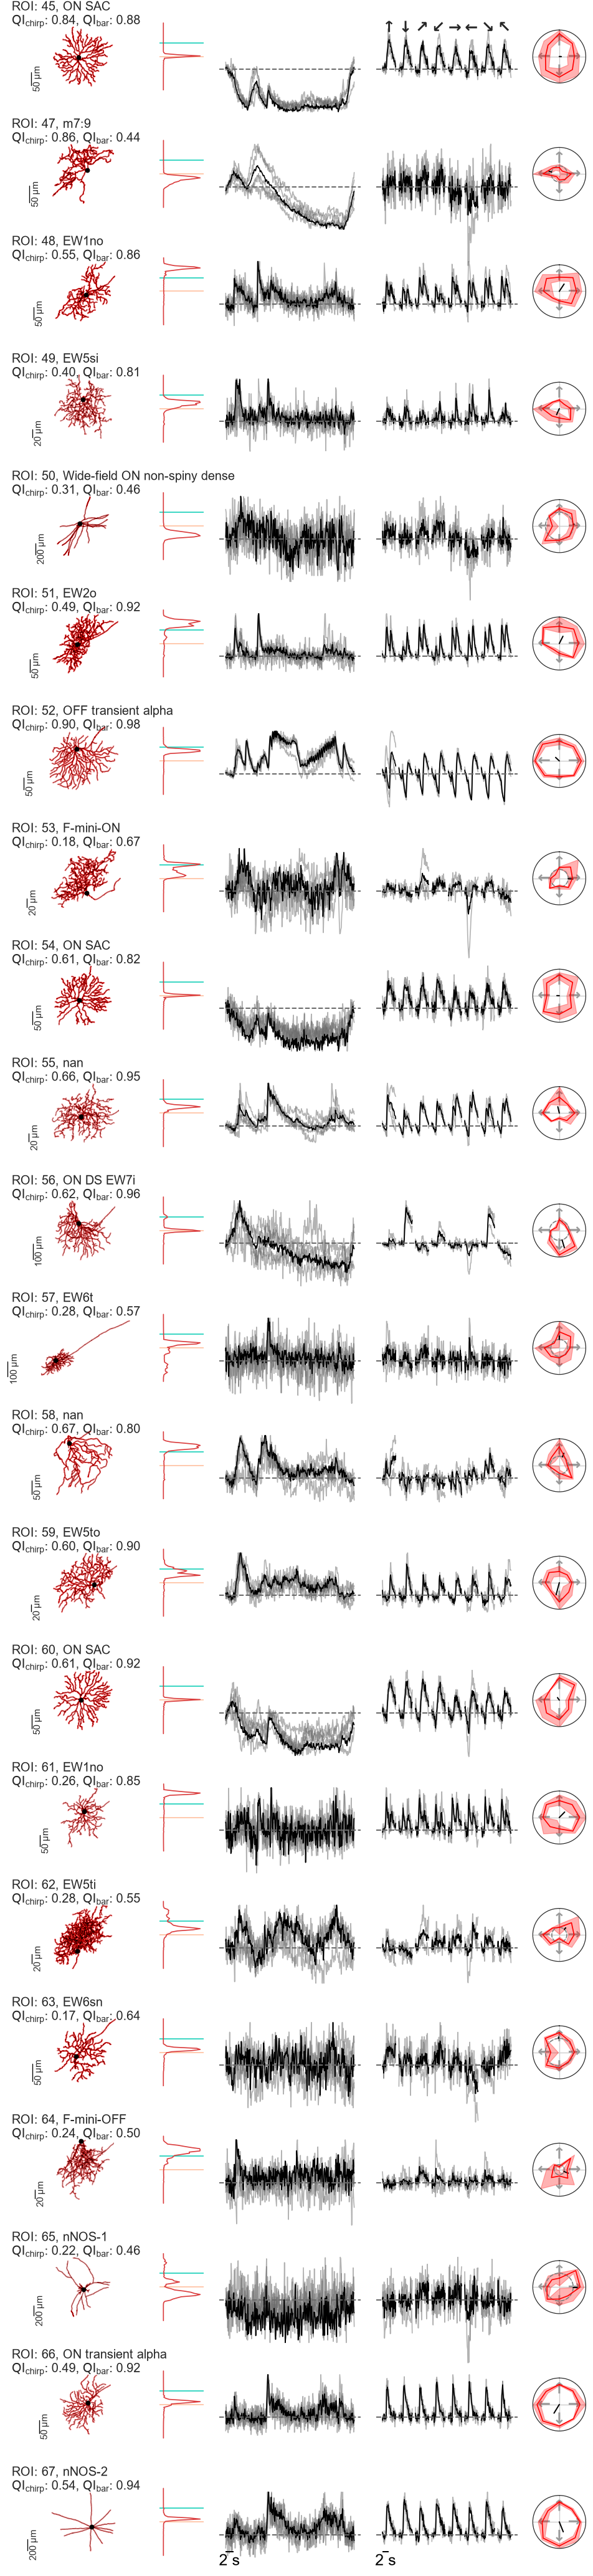

CPU times: total: 2min 35s
Wall time: 2min 41s


In [8]:
%%time
batch_size = 22

for start in range(0, len(df_field), batch_size):
    df_batch = df_field.iloc[start:start + batch_size]
    stop = start + len(df_batch)

    fig, axs = plot_cells(df_batch, figsize=(8, 25), fontsize_factor=1.5)
    fig.savefig(f"{fig_dir}/responses_{field}_{start + 1}-{stop}.svg", bbox_inches="tight", transparent=True)
    plt.show()

In [9]:
from watermark import watermark
print(watermark())

Last updated: 2026-11-25T12:27:32.071218+01:00

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.18.1

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
CPU cores   : 8
Architecture: 64bit

